In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from scipy.stats.contingency import association


In [2]:
data_source = 'dataset.csv'

In [197]:
df = pd.read_csv(data_source)

### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? The top 10 in order where being a best-seller is more prevalent are:
    1. Grocery 
    2. Health & PersonalCare 
    3. Baby 
    4. Sports & Outdoors 
    5. Power & Hand Tools 
    6. Beauty 
    7. Pet Supplies 
    8. Arts & Crafts 
    9. Women 
    10. Men


In [66]:
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])

In [67]:
crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213



2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category. Chi-square has no values smaller than 0.05, meaning the values are independent.
    - Compute Cramér's V to understand the strength of association between best-seller status and category. Cramer's V shows 0.12 which points to weak association.

In [71]:
_, chi2_p_value, _, expected_freq = chi2_contingency(crosstab_result)
for lst in expected_freq:
     for value in lst:
          if value < 0.05:
               print(lst)

In [72]:
# Computing the association between variables in 'crosstab_result' using the "cramer" method
association(crosstab_result, method="cramer")

0.1222829439760564

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

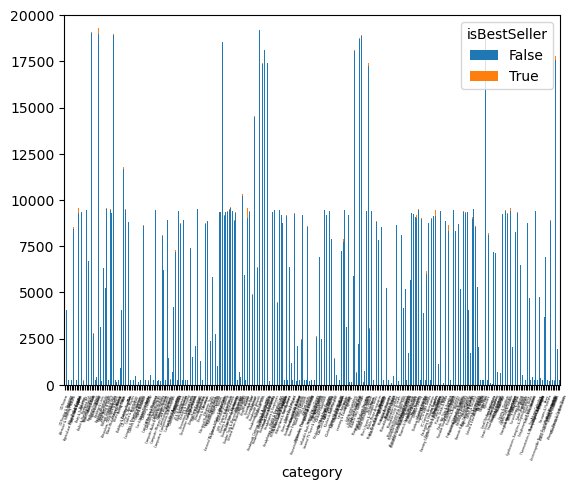

In [79]:
crosstab_result.plot(kind="bar", stacked=True)
plt.ylim(0, 20000)
plt.plot(figsize=(20, 15))
plt.xticks(rotation=70, fontsize=2)
plt.show()

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*





In [94]:
def tukeys_test_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1
    
    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Identify the outliers
    non_outliers = data[(data >= lower_bound) | (data <= upper_bound)]
    
    return non_outliers

In [95]:
masked_df = tukeys_test_outliers(df['price'])

In [103]:
df['price'] = masked_df

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization. There are some extreme outliers that are skewing the analysis.
    - Which product category tends to have the highest median price? Don't filter here by top categories. Judging by the chartn tell that Sports & Outdoors, Fragances and Men have the highest median price 

In [219]:
index = df['category'].value_counts().head(20).index

In [222]:
mask = df['category'].isin(index)
filtered_df = df[mask]

C:\Users\Santi\AppData\Local\Temp\ipykernel_20340\3944817122.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(filtered_df, x='category' , y='price', order=index, palette="coolwarm")


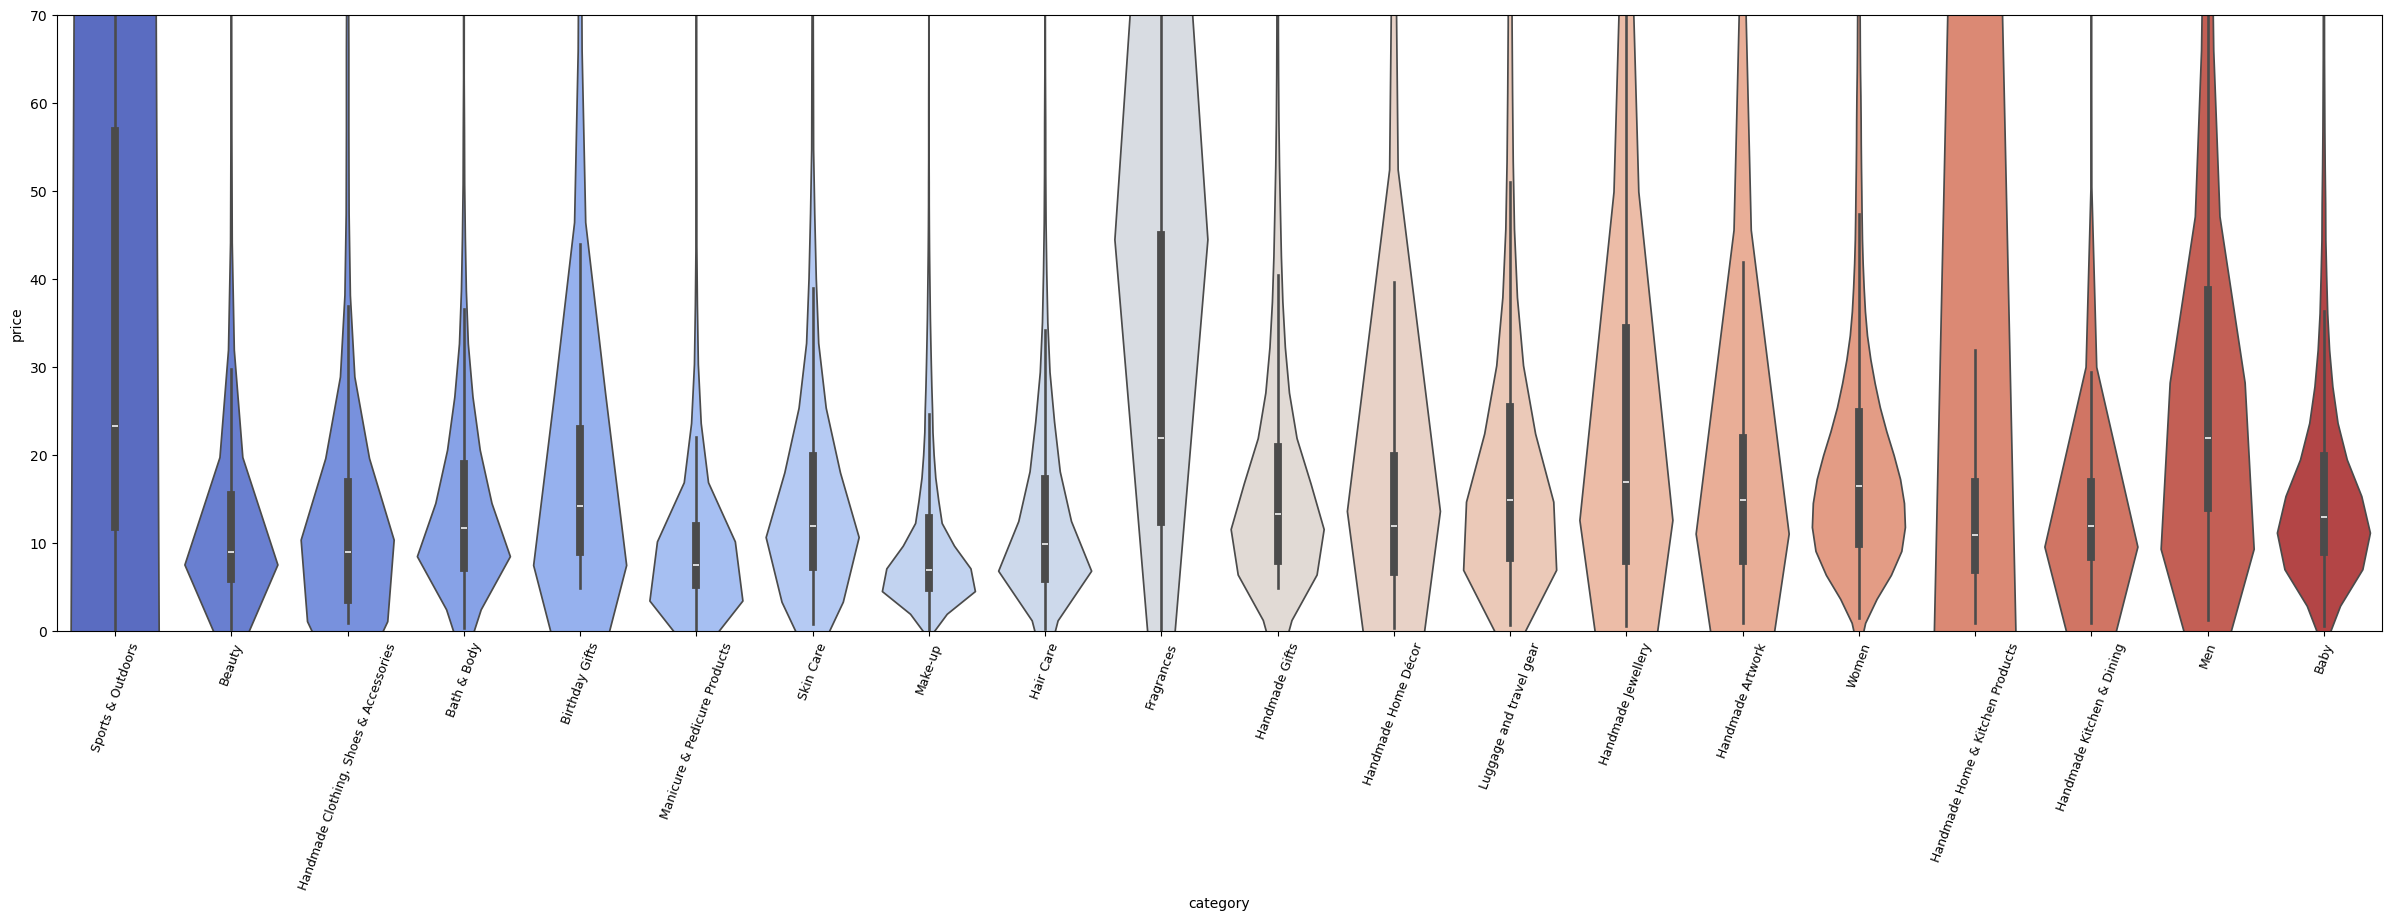

In [231]:
plt.figure(figsize= (30, 8))
sns.violinplot(filtered_df, x='category' , y='price', order=index, palette="coolwarm")
plt.xticks(rotation=70, fontsize=9)
plt.ylim(0, 70)
plt.show()

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories. Sports & Outdoors

In [234]:
index = df['category'].value_counts().head(10).index
mask = df['category'].isin(index)
filtered_df = df[mask]

C:\Users\Santi\AppData\Local\Temp\ipykernel_20340\1260178919.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(filtered_df, x='category' , y='price', order=index, palette="coolwarm")


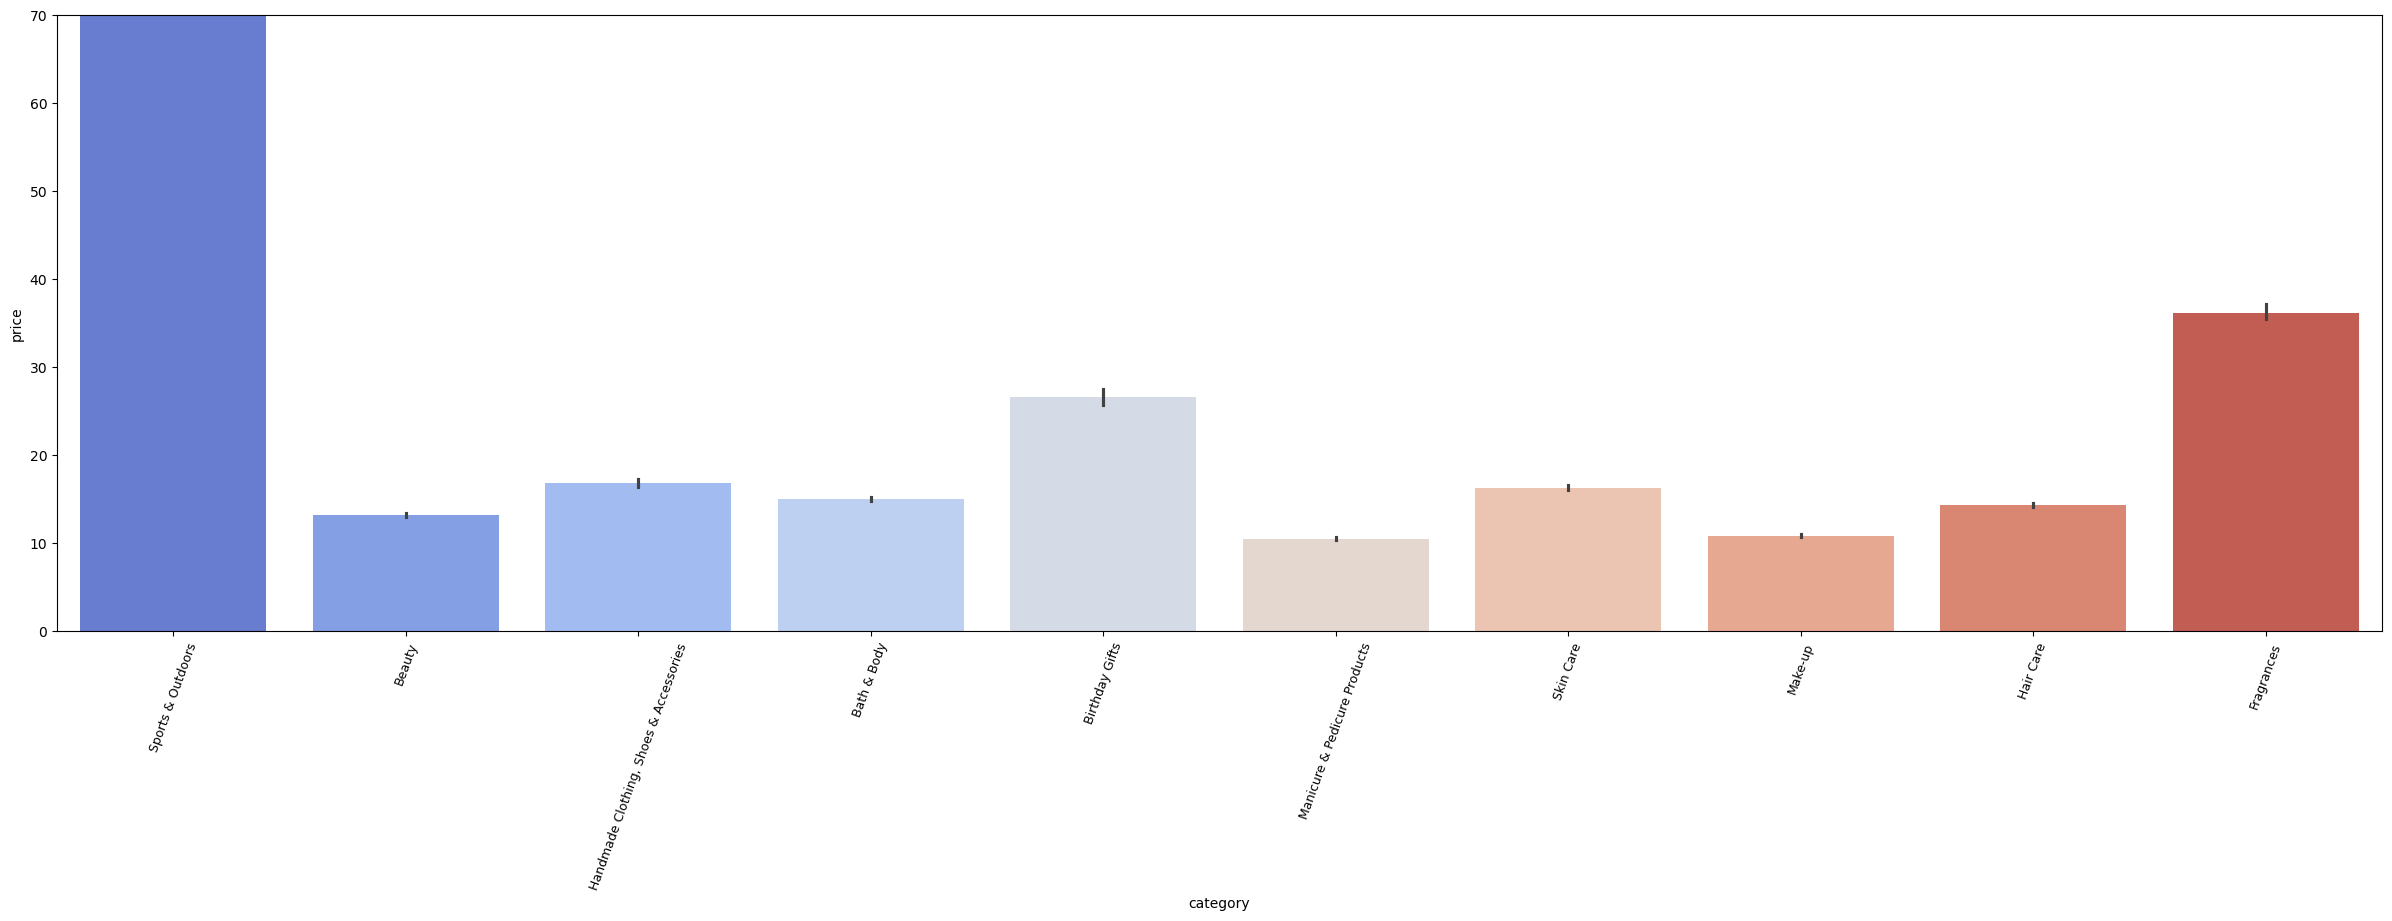

In [235]:
plt.figure(figsize= (30, 8))
sns.barplot(filtered_df, x='category' , y='price', order=index, palette="coolwarm")
plt.xticks(rotation=70, fontsize=9)
plt.ylim(0, 70)
plt.show()

3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories. Sports & Outdoors

C:\Users\Santi\AppData\Local\Temp\ipykernel_20340\1426695535.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(filtered_df, x='category' , y='price', order=index, palette="coolwarm")


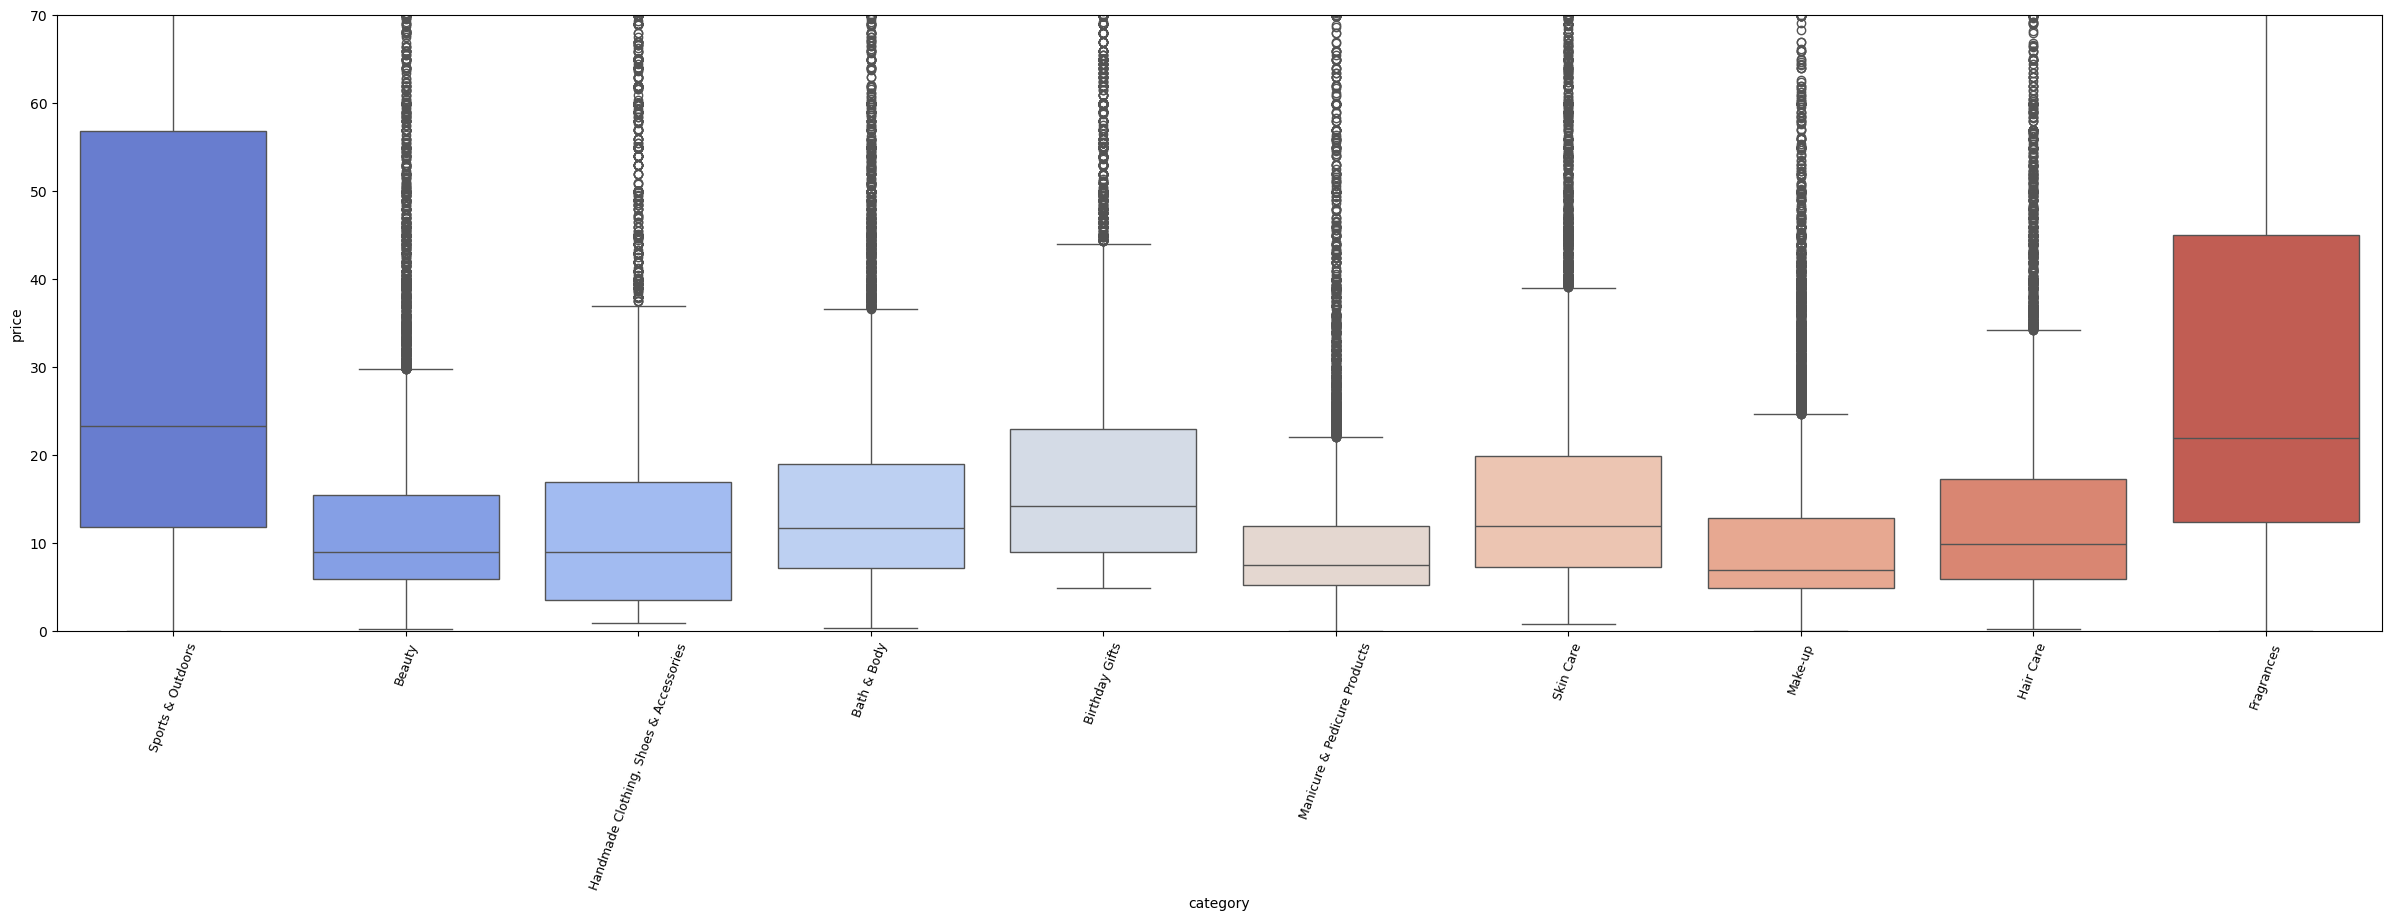

In [236]:
index = df['category'].value_counts().head(10).index
mask = df['category'].isin(index)
filtered_df = df[mask]

plt.figure(figsize= (30, 8))
sns.boxplot(filtered_df, x='category' , y='price', order=index, palette="coolwarm")
plt.xticks(rotation=70, fontsize=9)
plt.ylim(0, 70)
plt.show()

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating? Chi Square indicates that the variables are related, however Cramer's result is 0,15 which is a weak correlation.
	



In [237]:
crosstab_result = pd.crosstab(df['price'], df['stars'])

In [242]:
crosstab_result

stars,0.0,1.0,1.1,1.2,1.3,1.4,1.5,1.6,1.7,1.8,...,4.1,4.2,4.3,4.4,4.5,4.6,4.7,4.8,4.9,5.0
price,,,,,,,,,,,,,,,,,,,,,
0.00,0,0,0,0,0,0,0,0,0,0,...,1,1,1,0,1,5,7,2,0,1
0.01,613,5,0,0,0,0,1,0,0,0,...,4,2,2,0,0,5,1,1,0,18
0.02,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
0.03,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
0.04,12,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22933.42,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
23482.73,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
24674.59,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [240]:
_, chi2_p_value, _, expected_freq = chi2_contingency(crosstab_result)
expected_freq

array([[1.00312279e+01, 6.94370841e-02, 2.45534244e-05, ...,
        3.42585746e-01, 9.06921651e-02, 1.05163953e+00],
       [3.48083607e+02, 2.40946682e+00, 8.52003825e-04, ...,
        1.18877254e+01, 3.14701813e+00, 3.64918918e+01],
       [3.51092975e+00, 2.43029794e-02, 8.59369853e-06, ...,
        1.19905011e-01, 3.17422578e-02, 3.68073837e-01],
       ...,
       [5.01561393e-01, 3.47185421e-03, 1.22767122e-06, ...,
        1.71292873e-02, 4.53460826e-03, 5.25819767e-02],
       [5.01561393e-01, 3.47185421e-03, 1.22767122e-06, ...,
        1.71292873e-02, 4.53460826e-03, 5.25819767e-02],
       [5.01561393e-01, 3.47185421e-03, 1.22767122e-06, ...,
        1.71292873e-02, 4.53460826e-03, 5.25819767e-02]])

In [241]:
association(crosstab_result, method="cramer")

0.15350264705482008

2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 

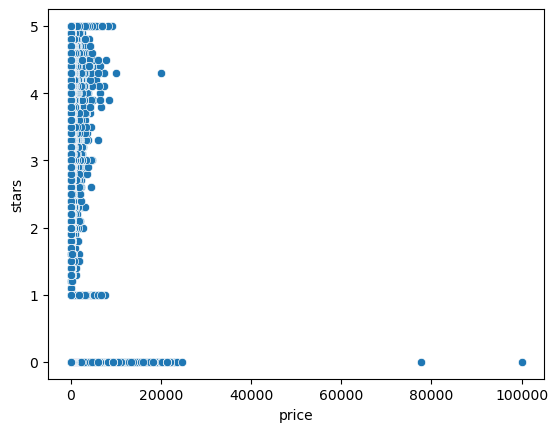

In [243]:
sns.scatterplot(data=df, x='price', y='stars')
plt.show()

In [247]:
df_numerical = df.select_dtypes('number')

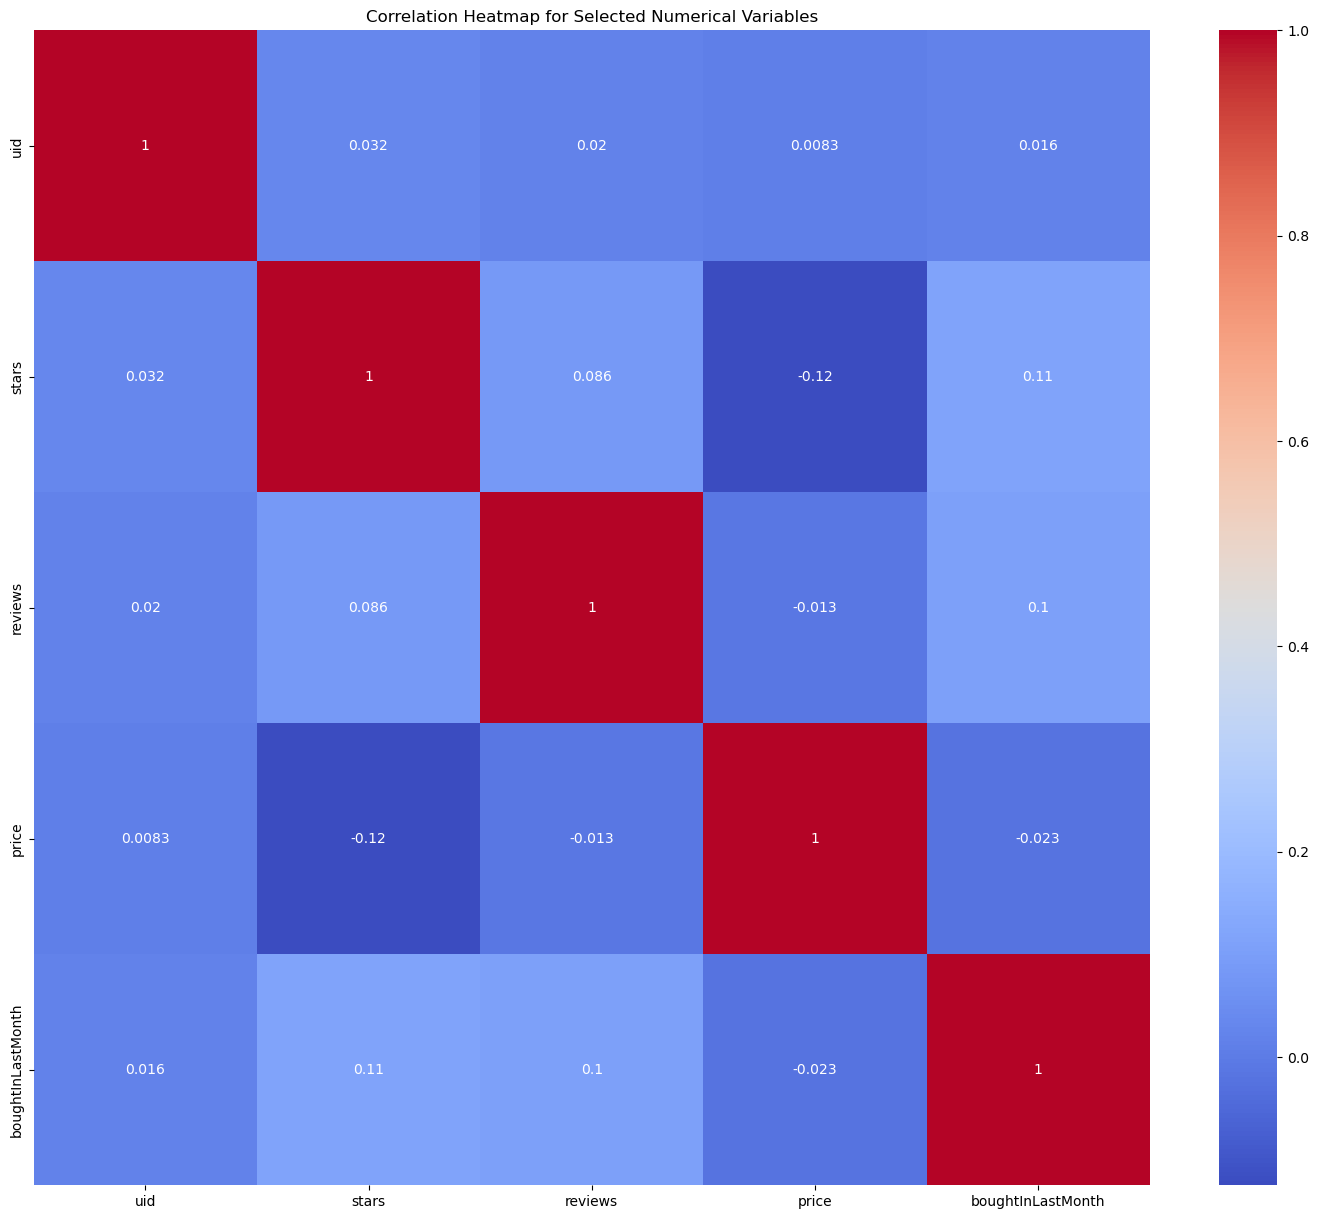

In [248]:
correlation_matrix = df_numerical.corr()

# Setting up the matplotlib figure with an appropriate size
plt.figure(figsize=(18, 15))

# Drawing the heatmap for the numerical columns
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")

plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()

In [244]:
import statsmodels.api as sm

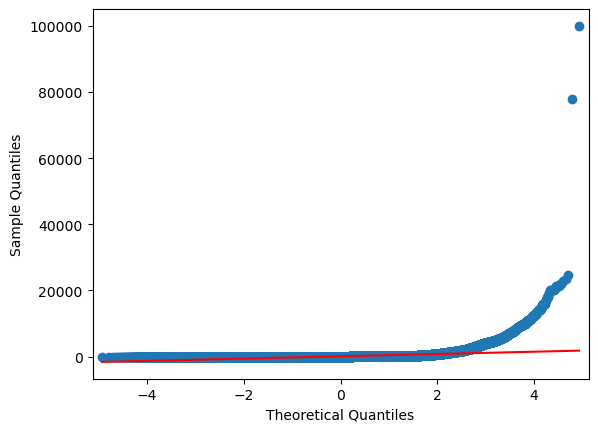

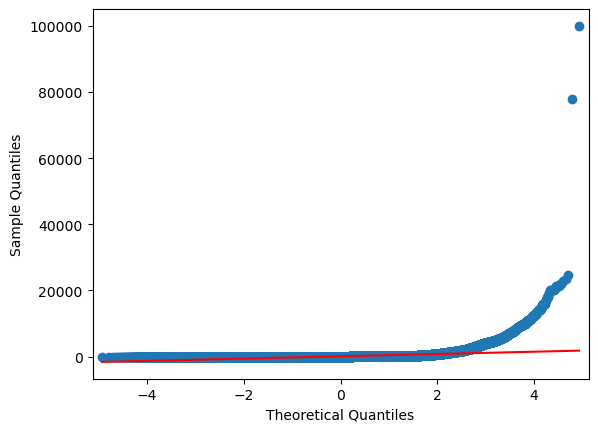

In [245]:
sm.qqplot(df['price'], line='s')